# Opción 1 — Longitud total (LT) por diámetro máximo de Feret

Reemplaza el esqueleto por **una sola medida**: el par de puntos más alejado del contorno de la máscara (se busca sobre los vértices de la envolvente convexa, que son pocos).

Pipeline: YOLO-seg → máscara → limpieza → (apertura opcional) → mayor contorno → convex hull → par de vértices a máxima distancia → `LT_recta_cm = dist_px / px_por_cm`.
La escala `px_por_cm` sale del lado del ArUco (ID 17, 5 cm) como en `fish_length_cm_wrapper.ipynb`. Las funciones compartidas están en `fish_length_utils.py`.

In [1]:
%pip install -q numpy scipy opencv-contrib-python scikit-image matplotlib pandas ultralytics

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Acceso denegado: 'c:\\Users\\juanm\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import fish_length_utils as U

# ---------------- parámetros ----------------
N_IMAGENES = None            # None = todas las imágenes de examples/; o un entero (primeras N)
CARPETA_IMAGENES = U.EXAMPLES_DIR
WEIGHTS = U.WEIGHTS
CONF, IMGSZ = U.CONF, U.IMGSZ
ARUCO_ID, TAMANO_ARUCO_CM = U.ARUCO_ID, U.TAMANO_ARUCO_CM
KERNEL_APERTURA = 15         # tamaño (px) de la apertura morfológica elíptica; 0 = sin apertura
SALIDA_IMGS = Path("outputs/opcion1")
SALIDA_CSV = Path("outputs/resultados_opcion1.csv")

## Diámetro de Feret

In [3]:
def diametro_feret(contorno):
    """Diámetro máximo de Feret de un contorno.

    Calcula la envolvente convexa y, por fuerza bruta sobre sus vértices (pocos), el par de puntos a mayor
    distancia. Devuelve (dist_px, punto_a, punto_b, hull) con los puntos como arrays (2,) float y hull (M, 2)."""
    hull = cv2.convexHull(contorno).reshape(-1, 2).astype(np.float64)
    d = np.linalg.norm(hull[:, None, :] - hull[None, :, :], axis=2)
    i, j = np.unravel_index(np.argmax(d), d.shape)
    return float(d[i, j]), hull[i], hull[j], hull


def medir_feret(mask, px_por_cm, kernel_apertura=0):
    """LT por Feret sobre la máscara limpia (con apertura si `kernel_apertura` > 0). Devuelve dict con
    LT_cm, dist_px, extremos, hull, contorno y tiempo de cómputo (s)."""
    t = U.cronometro()
    m = U.limpiar_mascara(mask)
    m = U.apertura(m, kernel_apertura)
    contorno = U.mayor_contorno(m)
    dist, a, b, hull = diametro_feret(contorno)
    return dict(LT_cm=dist / px_por_cm, dist_px=dist, a=a, b=b, hull=hull, contour=contorno, tiempo_s=t())

## Procesamiento de todas las imágenes

In [4]:
model = U.cargar_modelo(WEIGHTS)
filas, anotadas = [], {}

for path in U.listar_imagenes(CARPETA_IMAGENES, N_IMAGENES):
    prep = U.preparar_imagen(path, model, CONF, IMGSZ, ARUCO_ID, TAMANO_ARUCO_CM)
    base = dict(imagen=path.name, px_por_cm=prep["px_por_cm"], estado=prep["estado"], kernel_apertura=KERNEL_APERTURA,
                conf=CONF, imgsz=IMGSZ, aruco_id=ARUCO_ID, tamano_aruco_cm=TAMANO_ARUCO_CM)
    if prep["estado"] != "ok":
        print(f"{path.name}: saltada ({prep['estado']})")
        filas.append(dict(base, pez=None))
        continue

    peces = []
    for k, (m, score) in enumerate(zip(prep["masks"], prep["confs"])):
        sin = medir_feret(m, prep["px_por_cm"], 0)
        con = medir_feret(m, prep["px_por_cm"], KERNEL_APERTURA)
        filas.append(dict(base, pez=k, score=round(score, 4),
                          LT_feret_cm=round(sin["LT_cm"], 3), LT_feret_apertura_cm=round(con["LT_cm"], 3),
                          tiempo_feret_s=round(sin["tiempo_s"], 5), tiempo_feret_apertura_s=round(con["tiempo_s"], 5)))
        capas = [dict(tipo="poligono", pts=sin["hull"], color=U.COLOR_HULL, grosor=2),
                 dict(tipo="linea", pts=[sin["a"], sin["b"]], color=U.COLOR_CAMINO),
                 dict(tipo="puntos", pts=[sin["a"], sin["b"]], color=U.COLOR_EXTREMOS)]
        if KERNEL_APERTURA:
            capas += [dict(tipo="linea", pts=[con["a"], con["b"]], color=U.COLOR_ALT, grosor=2),
                      dict(tipo="puntos", pts=[con["a"], con["b"]], color=U.COLOR_ALT, grosor=2)]
        peces.append(dict(contour=sin["contour"], capas=capas,
                          texto=[f"{score:.2f} | LT {sin['LT_cm']:.1f} cm"] +
                                ([f"apertura {KERNEL_APERTURA}px: {con['LT_cm']:.1f} cm"] if KERNEL_APERTURA else [])))
        print(f"{path.name} pez {k}: Feret {sin['LT_cm']:.2f} cm | con apertura {con['LT_cm']:.2f} cm")

    out = U.dibujar_resultados(prep["img"], peces, [prep["aruco_corners"][prep["aruco_idx"]]], TAMANO_ARUCO_CM)
    U.guardar_rgb(out, SALIDA_IMGS / path.name)
    anotadas[path.name] = out

cero_peces.jpg: saltada (sin_aruco)
example (1).jpg pez 0: Feret 31.42 cm | con apertura 31.39 cm
example (1).jpg pez 1: Feret 27.52 cm | con apertura 27.37 cm
example (10).jpg pez 0: Feret 18.82 cm | con apertura 18.82 cm
example (11).jpg pez 0: Feret 25.96 cm | con apertura 25.88 cm
example (11).jpg pez 1: Feret 18.73 cm | con apertura 18.69 cm
example (11).jpg pez 2: Feret 19.94 cm | con apertura 19.83 cm
example (2).jpg pez 0: Feret 35.19 cm | con apertura 35.19 cm
example (3).jpg pez 0: Feret 27.55 cm | con apertura 27.52 cm
example (4).jpg pez 0: Feret 15.86 cm | con apertura 15.74 cm
example (4).jpg pez 1: Feret 20.00 cm | con apertura 19.75 cm
example (5).jpg: saltada (sin_peces)
example (6).jpg pez 0: Feret 18.92 cm | con apertura 18.90 cm
example (6).jpg pez 1: Feret 17.03 cm | con apertura 17.02 cm
example (6).jpg pez 2: Feret 21.13 cm | con apertura 21.09 cm
example (7).jpg: saltada (sin_peces)
example (8).jpg pez 0: Feret 17.02 cm | con apertura 14.53 cm
example (9).jpg pe

In [5]:
df = pd.DataFrame(filas)
SALIDA_CSV.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SALIDA_CSV, index=False)
print(f"CSV guardado en {SALIDA_CSV} ({len(df)} filas)")
df

CSV guardado en outputs\resultados_opcion1.csv (20 filas)


,imagen,px_por_cm,estado,kernel_apertura,conf,imgsz,aruco_id,tamano_aruco_cm,pez,score,LT_feret_cm,LT_feret_apertura_cm,tiempo_feret_s,tiempo_feret_apertura_s
0,cero_peces.jpg,NaN,sin_aruco,15,0.3,640,17,5.0,NaN,NaN,NaN,NaN,NaN,NaN
1,example (1).jpg,16.303056,ok,15,0.3,640,17,5.0,0.0,0.7259,31.422,31.391,0.03397,0.04769
2,example (1).jpg,16.303056,ok,15,0.3,640,17,5.0,1.0,0.5786,27.519,27.374,0.03516,0.05637
3,example (10).jpg,97.571352,ok,15,0.3,640,17,5.0,0.0,0.9219,18.824,18.821,0.49269,0.59043
4,example (11).jpg,15.152978,ok,15,0.3,640,17,5.0,0.0,0.7000,25.960,25.884,0.02413,0.03255
5,example (11).jpg,15.152978,ok,15,0.3,640,17,5.0,1.0,0.4240,18.731,18.688,0.02172,0.03272
6,example (11).jpg,15.152978,ok,15,0.3,640,17,5.0,2.0,0.3168,19.944,19.829,0.03012,0.04255
7,example (2).jpg,22.040458,ok,15,0.3,640,17,5.0,0.0,0.9574,35.193,35.188,0.03842,0.05731
8,example (3).jpg,18.407064,ok,15,0.3,640,17,5.0,0.0,0.9254,27.548,27.521,0.04068,0.05423
9,example (4).jpg,14.580849,ok,15,0.3,640,17,5.0,0.0,0.6579,15.858,15.735,0.02205,0.03069


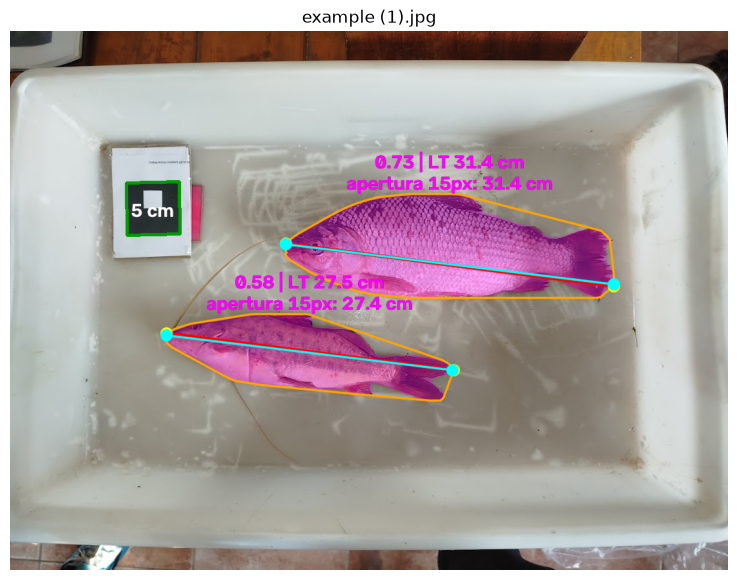

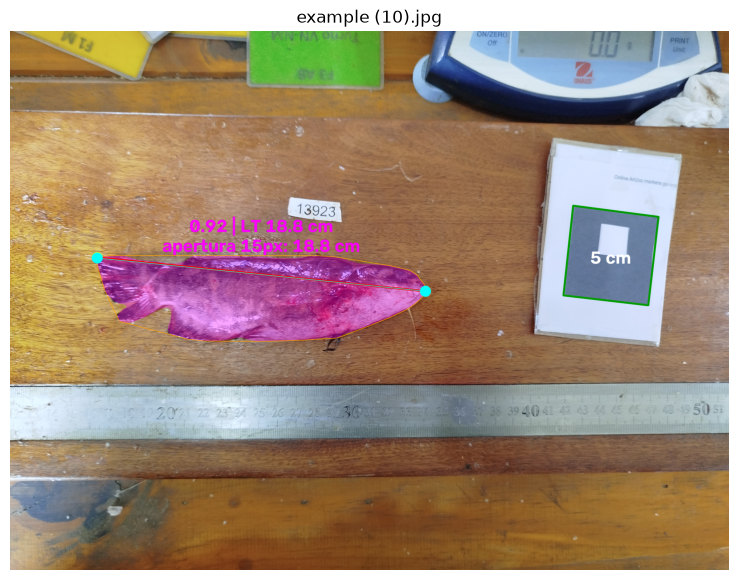

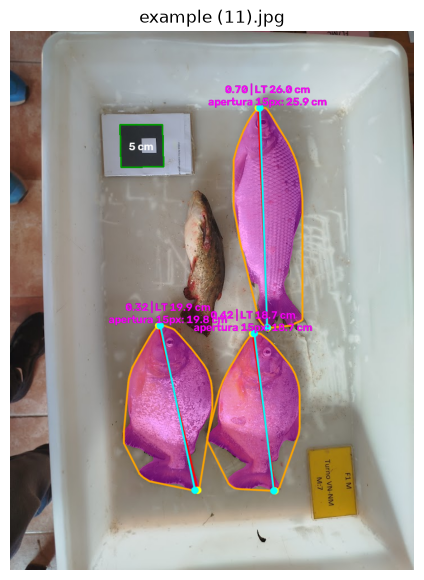

In [6]:
# Vista previa de las primeras imágenes anotadas
for nombre, im in list(anotadas.items())[:3]:
    plt.figure(figsize=(10, 7)); plt.imshow(im); plt.title(nombre); plt.axis("off"); plt.show()

## Resumen y limitaciones

**Resultados** (`outputs/resultados_opcion1.csv`, imágenes en `outputs/opcion1/`): 16 peces medidos en 13 imágenes de `examples/` (`cero_peces.jpg` sin ArUco; `example (5)` y `(7)` sin peces detectados con `conf=0.3`). El cómputo del Feret es de ~20–40 ms por pez (0.4 s en la imagen de 4000×3000).

**Observaciones**
- Es una medida **recta y única**: no se ve afectada por ramas espurias ni por la curva en S del esqueleto, pero **subestima** la LT en peces curvados (la LT real sigue el cuerpo) y no distingue entre hocico/cola y cualquier otro par de puntos lejanos.
- **Aletas extendidas**: una aleta dorsal/pectoral/caudal muy abierta puede aportar uno de los extremos del Feret y sobreestimar la LT; la apertura morfológica (15 px) la reduce pero con efectos laterales.
- **Cola plegada o fina**: la apertura **recorta los lóbulos caudales finos** y acorta la LT (p. ej. `example (8)`: 17.0 → 14.5 cm; `example (9)`: 17.5 → 14.8 cm). En peces con aletas poco salientes el cambio es <0.3 cm. Con apertura conviene un kernel pequeño o no usarla.
- **Calibración**: `px_por_cm` es un único factor (lado medio del ArUco): no corrige perspectiva. En `mal_angulo.jpg` el ArUco sale con ~2 px/cm (detección/ángulo erróneos) y la LT resulta absurda (~166 cm); hay que validar la calibración.
- El score de segmentación bajo (<0.5) suele correlacionar con máscaras incompletas y por lo tanto Feret poco confiable.